# 03 — Model Training & Evaluation
**Project:** Fake News Detection Using Natural Language Processing

This notebook trains and evaluates the **TF-IDF + Logistic Regression** classifier on the combined dataset:
- **Train / Test Split:** 80% Training, 20% Testing (`random_state=42`, `stratify=y`)
- **TF-IDF Configuration:** `max_features=30000`, `ngram_range=(1, 2)`, `min_df=2`, `sublinear_tf=True`, `stop_words="english"`
- **Classifier:** `LogisticRegression(max_iter=2000)`
- **Evaluation Metrics:** Accuracy, Precision, Recall, F1 Score, Classification Report, and Confusion Matrix heatmap

In [1]:
import sys
from pathlib import Path
import joblib
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import train_test_split

PROJECT_ROOT = Path("..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from backend.model_utils import clean_text

## 1. Load & Prepare Dataset

In [2]:
DATASET_DIR = PROJECT_ROOT / "dataset"
FAKE_PATH = DATASET_DIR / "Fake.csv"
TRUE_PATH = DATASET_DIR / "True.csv"

if not FAKE_PATH.is_file() or not TRUE_PATH.is_file():
    raise FileNotFoundError(
        "Please place Fake.csv and True.csv inside 'dataset/' before running model evaluation."
    )

fake_df = pd.read_csv(FAKE_PATH)
true_df = pd.read_csv(TRUE_PATH)

fake_df["label"] = 0
true_df["label"] = 1

df = pd.concat([fake_df, true_df], axis=0, ignore_index=True)
df["title"] = df["title"].fillna("").astype(str)
df["text"] = df["text"].fillna("").astype(str)

# Remove duplicates and shuffle
df = df.drop_duplicates(subset=["title", "text"], keep="first").reset_index(drop=True)
df = df.sample(frac=1.0, random_state=42).reset_index(drop=True)

# Create content and apply shared NLP preprocessing
df["content"] = (df["title"] + " " + df["text"]).apply(clean_text)
df = df[df["content"].str.len() > 0].reset_index(drop=True)

print(f"Prepared dataset size: {len(df):,} articles")

Prepared dataset size: 39,100 articles


## 2. Stratified 80/20 Train-Test Split & TF-IDF Vectorization

In [3]:
X = df["content"]
y = df["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

vectorizer = TfidfVectorizer(
    max_features=30000,
    ngram_range=(1, 2),
    min_df=2,
    sublinear_tf=True,
    stop_words="english",
)

X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

print("X_train_tfidf shape:", X_train_tfidf.shape)
print("X_test_tfidf shape: ", X_test_tfidf.shape)

X_train_tfidf shape: (31280, 30000)
X_test_tfidf shape:  (7820, 30000)


## 3. Train Logistic Regression & Compute Metrics

In [4]:
model = LogisticRegression(max_iter=2000, random_state=42)
model.fit(X_train_tfidf, y_train)

y_pred = model.predict(X_test_tfidf)

acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print(f"Accuracy  : {acc * 100:.2f}%")
print(f"Precision : {prec * 100:.2f}%")
print(f"Recall    : {rec * 100:.2f}%")
print(f"F1 Score  : {f1 * 100:.2f}%\n")
print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=["FAKE (0)", "REAL (1)"], digits=4))

Accuracy  : 99.02%
Precision : 98.51%
Recall    : 99.69%
F1 Score  : 99.10%

Classification Report:
              precision    recall  f1-score   support

    FAKE (0)     0.9963    0.9821    0.9892      3581
    REAL (1)     0.9851    0.9969    0.9910      4239

    accuracy                         0.9902      7820
   macro avg     0.9907    0.9895    0.9901      7820
weighted avg     0.9902    0.9902    0.9901      7820



## 4. Confusion Matrix Visualization

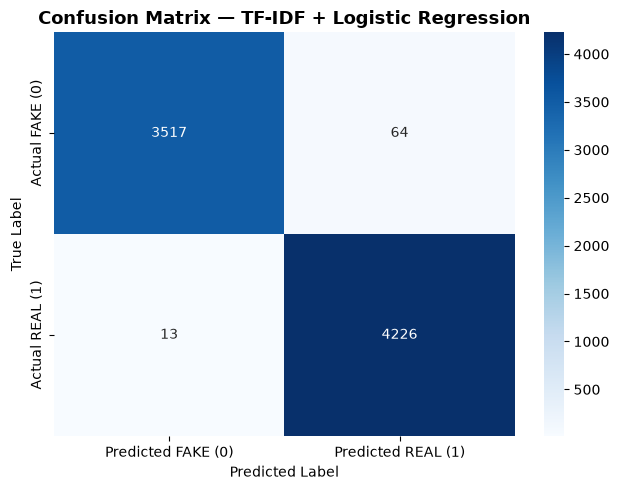

In [5]:
cm = confusion_matrix(y_test, y_pred)

fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Predicted FAKE (0)", "Predicted REAL (1)"],
    yticklabels=["Actual FAKE (0)", "Actual REAL (1)"],
    ax=ax,
)
ax.set_title("Confusion Matrix — TF-IDF + Logistic Regression", fontsize=13, fontweight="bold")
ax.set_ylabel("True Label")
ax.set_xlabel("Predicted Label")
plt.tight_layout()
plt.show()